In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Implementing RNNs

that section wrote down a recurrent language model and counted its
parameters, but did not train it. Two questions remain: how its equations
become working code, and whether a hidden state predicts *The Time
Machine* better than the counts of that section. The model fits in three equations: look up the
embedding of the current token, update the hidden state from it and from
the previous state, and map the new state to scores over the vocabulary.
The code for these equations keeps one contract. At each time step the
model consumes one token per sequence and the previous hidden state, and it
returns $|\mathcal{V}|$ logits per sequence and a new state of the same
shape as the old one. Because the shapes do not change from step to step,
the same step applies to a sequence of any length.

We first implement this contract with plain tensor operations, so that
every parameter and every shape is visible, and then hand it to the
recurrent layer that each framework provides. Training needs one addition
that the equations do not show. The gradient passes through the same
transition once per time step and can become large enough to undo much of
the progress of training in a single update. We therefore clip its norm
before every update. We then measure the trained model against the count-based
$n$-gram models of that section on the same text, and let
it generate text.

In [ ]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [ ]:
import collections
import time

## An RNN Language Model from Scratch

The model has three parts, and we implement each as its own class or method:
a *recurrent cell* that updates the hidden state one time step at a time, an
embedding that turns token ids into the vectors the cell consumes, and an
output layer that maps each hidden state to a vector of logits over the
vocabulary.

### The Recurrent Cell

For a minibatch of $b$ sequences, let $\mathbf{X}_t \in \mathbb{R}^{b
\times d}$ hold their inputs at step $t$ and $\mathbf{H}_t \in
\mathbb{R}^{b \times h}$ their hidden states. The cell computes the
recurrence of that section with the tanh activation,

$$\mathbf{H}_t = \tanh(\mathbf{X}_t \mathbf{W}_{\textrm{xh}} + \mathbf{H}_{t-1} \mathbf{W}_{\textrm{hh}} + \mathbf{b}_\textrm{h}),$$

so each new state mixes the current input with the previous state through
two weight matrices, $\mathbf{W}_{\textrm{xh}} \in \mathbb{R}^{d \times
h}$ and $\mathbf{W}_{\textrm{hh}} \in \mathbb{R}^{h \times h}$, and a
bias $\mathbf{b}_\textrm{h} \in \mathbb{R}^h$. The `RNNScratch` class
holds these three parameters. The number of hidden units `num_hiddens` ($h$)
is a hyperparameter, and `num_inputs` ($d$) is the width of the vectors
arriving at each step, which will shortly be the embedding dimension.

As in that section, we register the weights with the framework's
parameter type, so that the optimizer finds them and the trainer can move
them to a GPU. Both weight matrices start from $\mathcal{N}(0, \sigma^2)$
with $\sigma = 0.01$, and the bias starts at zero. With weights this
small, the recurrent weight has spectral radius about $\sigma\sqrt{h}
\approx 0.11$, so the untrained cell forgets its state within a few steps,
and training grows the weights from there.

In [2]:
class RNNScratch(d2l.Module):
    """The RNN model implemented from scratch."""
    def __init__(self, num_inputs, num_hiddens, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.W_xh = nn.Parameter(
            d2l.randn(num_inputs, num_hiddens) * sigma)
        self.W_hh = nn.Parameter(
            d2l.randn(num_hiddens, num_hiddens) * sigma)
        self.b_h = nn.Parameter(d2l.zeros(num_hiddens))

The forward computation loops over the outermost axis of `inputs`, whose
shape is (`num_steps`, `batch_size`, `num_inputs`), applies the recurrence
once per time step, and collects the hidden state of every step. When no
initial state is supplied, the state starts at zero. The explicit Python
loop over time steps is the readable form of the recurrence.

In [3]:
@d2l.add_to_class(RNNScratch)
def forward(self, inputs, state=None):
    if state is None:
        # Initial state with shape: (batch_size, num_hiddens)
        state = d2l.zeros((inputs.shape[1], self.num_hiddens),
                          device=inputs.device)
    outputs = []
    for X in inputs:  # Shape of inputs: (num_steps, batch_size, num_inputs)
        state = d2l.tanh(d2l.matmul(X, self.W_xh) +
                         d2l.matmul(state, self.W_hh) + self.b_h)
        outputs.append(state)
    return outputs, state

We feed the cell a minibatch of two sequences of 100 steps each.

In [4]:
batch_size, num_inputs, num_hiddens, num_steps = 2, 16, 32, 100
rnn = RNNScratch(num_inputs, num_hiddens)
X = d2l.ones((num_steps, batch_size, num_inputs))
outputs, state = rnn(X)

The contract asks for one state per step, each with the shape
(`batch_size`, `num_hiddens`) of the state the cell started from. The two
helpers below check lengths and shapes; later sections use them as well.

In [5]:
def check_len(a, n):
    """Check the length of a list."""
    assert len(a) == n, f'list\'s length {len(a)} != expected length {n}'

def check_shape(a, shape):
    """Check the shape of a tensor."""
    assert a.shape == shape, \
            f'tensor\'s shape {a.shape} != expected shape {shape}'

check_len(outputs, num_steps)
check_shape(outputs[0], (batch_size, num_hiddens))
check_shape(state, (batch_size, num_hiddens))

### The Embedding Table

The cell consumes vectors, but our data pipeline delivers integer token ids.
Older treatments bridged the gap with a *one-hot encoding*: token $i$
becomes the length-$|\mathcal{V}|$ vector with a single 1 in position $i$,
and the input weights multiply that vector. With a vocabulary of 27
characters this is harmless. With our BPE vocabulary of $|\mathcal{V}| =
1{,}027$ ids it is wasteful, since each step multiplies a 1,027-wide vector
that is zero everywhere but one entry.

As in that section, we instead use an *embedding lookup*: a trainable
table $\mathbf{E} \in \mathbb{R}^{|\mathcal{V}| \times d}$ represents
token $i$ by its $i^\textrm{th}$ row, a $d$-dimensional vector that
gradient descent adjusts along with every other parameter. Multiplying a
one-hot vector by $\mathbf{E}$ selects a row of $\mathbf{E}$, so the lookup
computes the one-hot matrix product without materializing the zeros. A
one-hot encoding is thus an embedding whose table is fixed at the identity.
A trainable table lets the model choose the vector of each token.

The `RNNLMScratch` class assembles the language model around a cell `rnn`:
the embedding table `E` on the input side and an output layer (`W_hq`,
`b_q`) on the output side. The embedding dimension is read off the cell's
`num_inputs`, since the cell consumes what the embedding produces. The
embedding rows start at unit scale, as the 1s of a one-hot encoding would,
while the output weights start at scale $\sigma$ and the output bias at
zero. The logits of the untrained model are then close to zero, its
next-token distribution is close to uniform, and its perplexity is close to
$|\mathcal{V}|$.

The model inherits from `Classifier` the cross-entropy
loss, averaged over all tokens of a minibatch. Its validation step returns
only this loss, since the token accuracy that `Classifier` would add is not
what we monitor. The mean cross-entropy is the logarithm of the perplexity
(that section), so the validation perplexity is the
exponential of the trainer's mean validation loss.

In [6]:
class RNNLMScratch(d2l.Classifier):
    """The RNN-based language model implemented from scratch."""
    def __init__(self, rnn, vocab_size, lr=0.01, dropout=0, emb_dropout=0):
        super().__init__()
        self.save_hyperparameters()
        self.sigma = getattr(rnn, 'sigma', 0.01)  # Scale of the output weights
        self.init_params()

    def init_params(self):
        self.E = nn.Parameter(
            d2l.randn(self.vocab_size, self.rnn.num_inputs))
        self.W_hq = nn.Parameter(
            d2l.randn(self.rnn.num_hiddens, self.vocab_size) * self.sigma)
        self.b_q = nn.Parameter(d2l.zeros(self.vocab_size))

    def validation_step(self, batch):
        return self.loss(self(*batch[:-1]), batch[-1])

The minibatches sampled by our data pipeline have shape (`batch_size`,
`num_steps`). The `embedding` method looks up each id and transposes the
result to (`num_steps`, `batch_size`, `num_inputs`), the layout whose
outermost axis the cell's forward loop walks over.

In [7]:
@d2l.add_to_class(RNNLMScratch)
def embedding(self, X):
    # Output shape: (num_steps, batch_size, num_inputs)
    return self.E[X.T]

To confirm the equivalence claimed above, we check on a toy five-token
vocabulary that multiplying one-hot vectors into a table picks out the same
rows that indexing does.

In [8]:
W, ids = d2l.randn(5, 3), d2l.tensor([0, 2])
torch.allclose(F.one_hot(ids, 5).float() @ W, W[ids])

True

### The Output Layer

The last of the three equations turns each hidden state into scores for
the next token. The output layer computes $\mathbf{O}_t = \mathbf{H}_t
\mathbf{W}_{\textrm{hq}} + \mathbf{b}_\textrm{q}$ for every time step, with
$\mathbf{W}_{\textrm{hq}} \in \mathbb{R}^{h \times |\mathcal{V}|}$. Since
the same weights serve every step, one matrix product handles all of them:
the method stacks the states of all steps into a (`batch_size`,
`num_steps`, `num_hiddens`) tensor and multiplies it by
$\mathbf{W}_{\textrm{hq}}$, which gives logits of shape (`batch_size`,
`num_steps`, `vocab_size`) that line up with the target array. The
`forward` method chains the three parts together.

In [9]:
@d2l.add_to_class(RNNLMScratch)
def output_layer(self, rnn_outputs):
    # A list of per-step states, or a tensor whose first axis is time
    H = d2l.stack(list(rnn_outputs), 1)  # (batch_size, num_steps, num_hiddens)
    return d2l.matmul(H, self.W_hq) + self.b_q

@d2l.add_to_class(RNNLMScratch)
def forward(self, X, state=None):
    embs = F.dropout(self.embedding(X), self.emb_dropout, self.training)
    rnn_outputs, _ = self.rnn(embs, state)
    H = d2l.stack(list(rnn_outputs), 0)  # (num_steps, batch_size, num_hiddens)
    return self.output_layer(F.dropout(H, self.dropout, self.training))

A minibatch of token ids of shape (`batch_size`, `num_steps`) should come
out as one vector of logits per position. We check this with a vocabulary
of 1,024 ids, about the size of the one we train on.

In [10]:
model = RNNLMScratch(rnn, vocab_size=1024)
outputs = model(d2l.ones((batch_size, num_steps), dtype=d2l.int64))
check_shape(outputs, (batch_size, num_steps, 1024))

## Gradient Clipping

A recurrent network is deep in time. Backpropagating through $T$ time
steps multiplies $T$ Jacobians of the same transition, one per step, and
as in a deep feedforward network such a product can shrink or grow
exponentially with its length. that section analyzes both cases.
Vanishing gradients limit what the model can learn, but they do not break
training. Exploding gradients do, and they appear in our model early: the
gradient norm starts near 0.1, and within the first twenty or so updates it
jumps severalfold from one update to the next, in most runs past 1 and in
some past 10.

To see what a large gradient threatens, consider the length of one update.
A gradient step with learning rate $\eta$ moves the parameters
$\mathbf{x}$ to $\mathbf{x} - \eta\mathbf{g}$, a distance

$$\|(\mathbf{x} - \eta\mathbf{g}) - \mathbf{x}\| = \eta\|\mathbf{g}\|.$$

Thus the length of a step grows with the norm of the gradient. Gradient
descent works because, over a short step, the loss is close to its linear
approximation $f(\mathbf{x}) - \eta\|\mathbf{g}\|^2$, which decreases.
When $\|\mathbf{g}\|$ spikes, the step leaves the region where that
approximation holds, and the loss can jump instead of falling. One such
step can undo the progress of many updates. Shrinking $\eta$ until even the
rare spike is safe would slow every step to protect against a few.
*Gradient clipping* instead caps the norm on the occasions it is too large,
projecting $\mathbf{g}$ onto the ball of radius $\theta$:

$$\mathbf{g} \leftarrow \min\left(1, \frac{\theta}{\|\mathbf{g}\|}\right) \mathbf{g}.$$

A gradient with norm at most $\theta$ passes unchanged; a longer one is
scaled down to norm $\theta$ and keeps its direction. With $\theta = 1$, a
gradient of norm 10 becomes one tenth of itself. The norm
$\|\mathbf{g}\|$ is the Euclidean norm of the gradients of all parameters
of the model, stacked into one vector. Whenever it acts, clipping changes
the update, so training no longer follows the gradient, and its effect on
convergence is hard to analyze. It is standard nevertheless: recurrent
networks and large transformers alike are trained with it.
<!-- d2l:prose id=rnn-implementation-md-12 fw=mxnet, pytorch -->

The method below attaches to the `d2l.Trainer` class (see
that section): whenever a positive `gradient_clip_val` is
set, `fit_epoch` invokes it after the backward pass and before the parameter
update, rescaling each parameter's gradient in place. The scale factor
$\min(1, \theta/\|\mathbf{g}\|)$ is computed on the device, so clipping
does not force a synchronization with Python.

In [11]:
@d2l.add_to_class(d2l.Trainer)
def clip_gradients(self, grad_clip_val, model):
    params = [p for p in model.parameters() if p.requires_grad]
    norm = torch.sqrt(sum(torch.sum(p.grad ** 2) for p in params))
    scale = torch.clamp(grad_clip_val / norm, max=1.0)  # no `if` on the host
    for param in params:
        param.grad.mul_(scale)

## Training

The `d2l.TimeMachine` pipeline of that section downloads the
corpus, trains the BPE tokenizer on it, and serves minibatches of token-id
windows together with their shift-by-one targets. The corpus is 65,741 BPE
tokens long, and training window $i$ starts at token $i$. The pipeline
drops the 32 windows that straddle the split, so that no validation token
is ever a training target. The default split reserves only the first
10,000 windows for training, which suits quick
demonstrations but gives a model too little text (an exercise asks you to
watch what goes wrong). We therefore train on the first 50,000 windows,
most of the novella, and validate on the following 5,000.

In [12]:
data = d2l.TimeMachine(batch_size=1024, num_steps=32,
                       num_train=50000, num_val=5000)

Every window is $T = 32$ tokens long, and every forward pass starts from a
zero state, so gradients flow backward through at most 32 steps: the chain
of dependencies is *truncated* at the window boundary. The model learns
longer-range structure only insofar as it helps within a window. This
compromise is called truncated backpropagation through time, and
that section analyzes what it gives up. A common variant for long
sequences carries the final state of one chunk into the next instead of
resetting it. The carried state must then be detached from the computation
graph, so that gradients stop at the chunk boundary; otherwise the graph,
and the cost of each backward pass, would grow with every chunk.

### A Plain Model

We first train the model as built so far: an embedding of dimension $d =
64$ and a cell with $h = 128$ hidden units, 222,915 parameters in all, for
ten epochs of minibatch SGD at learning rate 4, clipping gradients to norm
$\theta = 1$, with no dropout. As in that section, training is
teacher-forced: every step conditions on the true prefix from the corpus.
We keep a copy of the embedding table, to see later how much training
changes it.

In [13]:
rnn = RNNScratch(num_inputs=64, num_hiddens=128)
model = RNNLMScratch(rnn, vocab_size=len(data.vocab), lr=4)

In [14]:
E_init = d2l.numpy(model.E).copy()

initial validation perplexity 1027


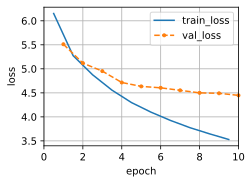

In [15]:
trainer = d2l.Trainer(max_epochs=10, gradient_clip_val=1, num_gpus=1)
ppl_init = math.exp(trainer.evaluate(model, data)['loss'])
print(f'initial validation perplexity {ppl_init:.0f}')
trainer.fit(model, data)

Before training, the validation perplexity is close to the vocabulary size
of 1,027, as expected from the near-uniform initial model. The board plots
the mean cross-entropy per token, the logarithm of the perplexity. Both
curves fall fast during the first epochs. Then they separate: the training
loss keeps falling, while the validation loss stops improving over the last
few epochs. After ten epochs the training perplexity is less than half the
validation perplexity: with 222,915 parameters for 50,000 training tokens,
more than four parameters per token, the model has started to memorize its
training text. The final validation perplexity is the exponential of the
last validation loss.

In [16]:
ppl_plain = math.exp(trainer.history['val_loss'][-1])
print(f'validation perplexity {ppl_plain:.1f}')

validation perplexity 85.4


A perplexity of about 90 may look poor next to the perplexity of about 6
of the character-level trigram in that section. The two numbers
cannot be compared: our model chooses among 1,027 BPE tokens per step, a
character model among 27 characters. Bits per byte
(that section, the equation) removes the dependence on
the tokenizer: it divides the total surprisal of a text by its length in
bytes, which here comes to $\log_2 \textrm{ppl}$ divided by the average
number of bytes per token. We measure the bytes per token on the 5,000
consecutive validation tokens that start the validation windows.

In [17]:
ids = d2l.numpy(data.X[data.num_train:data.num_train+data.num_val, 0]).tolist()
bytes_per_token = len(data.tokenizer.decode(ids).encode('utf-8')) / len(ids)
print(f'{bytes_per_token:.2f} bytes/token, '
      f'{math.log2(ppl_plain) / bytes_per_token:.2f} bits per byte')

2.78 bytes/token, 2.31 bits per byte


Each token covers about 2.8 bytes of text, and the plain model needs about
2.3 to 2.4 bits per byte.

### Embeddings under SGD

Overfitting is one problem of the plain model. A second one is hidden in
the embedding table. We measure how far each row of $\mathbf{E}$ moved
during training, relative to its initial length.

In [18]:
E_final = d2l.numpy(model.E)

In [19]:
change = (((E_final - E_init) ** 2).sum(1) / (E_init ** 2).sum(1)) ** 0.5
print(f'mean change of an embedding row: {change.mean():.1%} of its length')

mean change of an embedding row: 4.3% of its length


The rows barely move. Each row receives a gradient only from the positions
where its token occurs, and the loss averages over all $1{,}024 \times 32 =
32{,}768$ positions of a minibatch, so a token that occurs a few times
contributes a few parts in 32,768 of the gradient. A step of SGD moves
every parameter by the learning rate times its gradient, the same rate for
all, which is far too small for rows that start at unit scale. The cell
therefore reads its inputs through token vectors that stay close to their
random initial values; rows of tokens that never occur in the training
text do not move at all.

The input weights $\mathbf{W}_{\textrm{xh}}$ do learn, so a wider
embedding helps even if its rows stay close to random: with $d = 512$
instead of 64, $\mathbf{W}_{\textrm{xh}}$ has more random features of each
token to combine. Dropout (that section), applied to the
embeddings at rate 0.1 and to the hidden states before the output layer at
rate 0.5, counters the overfitting. An optimizer that
adapts the step to each parameter's gradients moves the rows much further,
as an exercise shows with Adam.

### A Wider Embedding with Dropout

`RNNLMScratch` already accepts the two dropout rates, which default to
zero. The new model has 740,355 parameters, most of them in the
$1{,}027 \times 512$ embedding table; everything else in the training
procedure stays the same. We time this run for a comparison at the end of
the section.

In [20]:
rnn = RNNScratch(num_inputs=512, num_hiddens=128)
model = RNNLMScratch(rnn, vocab_size=len(data.vocab), lr=4, dropout=0.5,
                     emb_dropout=0.1)

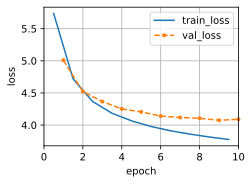

In [21]:
trainer = d2l.Trainer(max_epochs=10, gradient_clip_val=1, num_gpus=1)
t0 = time.perf_counter()
trainer.fit(model, data)
t_scratch = time.perf_counter() - t0

In [22]:
ppl_scratch = math.exp(trainer.history['val_loss'][-1])
print(f'validation perplexity {ppl_scratch:.1f}, '
      f'{math.log2(ppl_scratch) / bytes_per_token:.2f} bits per byte')

validation perplexity 59.7, 2.12 bits per byte


The validation perplexity falls to about 60, against about 90 for the
plain model; in bits per byte, about 2.1 against 2.3 to 2.4. The training loss on the board is
measured with dropout active, which raises it, so it no longer shows the
gap between training and validation directly. The validation loss is still
at or near its lowest after ten epochs.

### Comparison with Kneser–Ney

The best count-based model of that section is Kneser–Ney
smoothing in its interpolated form (that section,
the equation): it subtracts a discount from every observed
$n$-gram count and passes the freed probability to lower orders that count
distinct predecessors. `d2l.kneser_ney` counts the $n$-grams of a training
sequence and returns the natural log-probability of every token of another
sequence, given the tokens before it. We count the $n$-grams of the RNN's
50,000 training tokens, in the same BPE tokenization. We score the
validation tokens from the 33rd on, `val[32:]`, so that the RNN, below, can
read a full window of 32 validation tokens before each of them.

In [23]:
first_tokens = d2l.numpy(data.X[:, 0]).tolist()  # First token of each window
train = first_tokens[:data.num_train]
val = first_tokens[data.num_train:data.num_train + data.num_val]
lp_kns = {n: d2l.kneser_ney(train, val, len(data.vocab), n)[32:]
          for n in (2, 3, 4)}
for n, lp in lp_kns.items():
    bits = -sum(lp) / len(lp) / math.log(2)
    print(f'KN {n}-gram: {bits / bytes_per_token:.2f} bits per byte')
lp_kn = lp_kns[3]

KN 2-gram: 2.24 bits per byte
KN 3-gram: 2.09 bits per byte
KN 4-gram: 2.08 bits per byte


The trigram is much better than the bigram, and a fourth token of context
helps it little more. To compare the RNN token by token, we score the same
tokens `val[32:]` with it, each from the 32 validation tokens before it:
validation window $j$ starts at `val[j]`, so its last target is
`val[j + 32]`. (The validation loss on the board averages over all 32
positions of a window, and the first of them see only one or a few tokens
of context.)

In [24]:
start, stop = data.num_train, data.num_train + data.num_val - 32
targets = [int(y) for y in d2l.numpy(data.Y[start:stop, -1])]  # val[32:]

In [25]:
model.eval()
with torch.inference_mode():  # Log-probabilities at the last position
    logp = d2l.numpy(torch.cat([
        F.log_softmax(model(X.to(d2l.try_gpu()))[:, -1], -1)
        for X in data.X[start:stop].split(1024)]))

The two models make different mistakes. The RNN sees 32 tokens of context
but learns only from what it has seen in a few hundred SGD steps. The
counts see two tokens but remember every trigram of the training text.
Linear interpolation, $\lambda P_\textrm{RNN} + (1 - \lambda)
P_\textrm{KN}$, is how @Mikolov.Kombrink.Burget.ea.2011 combined
their RNN language models with Kneser–Ney models, choosing $\lambda$ on
held-out data. We fix $\lambda = 0.5$ instead of tuning it, close to the
best weight for this pair. A weighted average of two probability
distributions is a probability distribution, so the mixture is a language
model too.

In [26]:
lp_rnn = [logp[i, y] for i, y in enumerate(targets)]
lam = 0.5
lp_mix = [math.log(lam * math.exp(a) + (1 - lam) * math.exp(b))
          for a, b in zip(lp_rnn, lp_kn)]
for name, lp in [('RNN', lp_rnn), ('KN trigram', lp_kn), ('mixture', lp_mix)]:
    bits = -sum(lp) / len(lp) / math.log(2)
    print(f'{name}: {bits / bytes_per_token:.2f} bits per byte')

RNN: 2.12 bits per byte
KN trigram: 2.09 bits per byte
mixture: 2.03 bits per byte


The RNN alone comes within a few hundredths of a bit per byte of the
Kneser–Ney trigram, and the mixture beats both by a clear margin, because
the two models are confident on different tokens. Trained with Adam
(that section) instead of SGD and with slightly stronger embedding
dropout, the RNN alone also edges past the trigram; an exercise asks you to
try it. These numbers are higher than those in the table of
that section, which was computed on lowercased text with
letters only. Bits per byte compares tokenizers on the same text, and on
the raw text of this section the Kneser–Ney trigram needs about 2.1.

## Text Generation

A trained language model can continue a prefix (that section). The
`predict` method below first *warms up* on the prefix, feeding its tokens
one at a time to build up a hidden state without emitting anything. It then
generates `num_tokens` new tokens, each time turning the current logits
$\mathbf{o}$ into a choice of next token and feeding that token back in as
the next input.

The method offers the two simplest ways to make the choice. With
`temperature=0` it is *greedy* and takes the highest-scoring token.
Otherwise it *samples* token $i$ with probability proportional to
$\exp(o_i / \tau)$ for the temperature $\tau > 0$. At $\tau = 1$ this is
the model's own softmax distribution. Values below 1 sharpen the
distribution toward the greedy choice, and values above 1 flatten it toward
the uniform distribution. Each framework's sampler draws a fresh random
token on each call, so the samples differ from run to run.

In [27]:
@d2l.add_to_class(RNNLMScratch)
@torch.inference_mode()  # Generation needs no autograd graph
def predict(self, prefix, num_tokens, tok, device=None, temperature=0.0):
    outputs, state = tok.encode(prefix), None
    for i in range(len(outputs) - 1):  # Warm up on the prefix
        X = d2l.tensor([[outputs[i]]], device=device)
        _, state = self.rnn(self.embedding(X), state)
    for _ in range(num_tokens):  # Generate num_tokens continuation tokens
        X = d2l.tensor([[outputs[-1]]], device=device)
        rnn_outputs, state = self.rnn(self.embedding(X), state)
        logits = self.output_layer(rnn_outputs)[0, 0]
        if temperature == 0:  # Greedy: the highest-scoring token
            token = logits.argmax()
        else:  # Sample from the softmax of logits / temperature
            token = torch.distributions.Categorical(
                logits=logits / temperature).sample()
        outputs.append(int(token))
    return tok.decode(outputs)

We start with greedy decoding. The prefix is real text, not token ids: the
tokenizer trained by the pipeline (`data.tokenizer`) encodes it on the way
in and decodes the generated ids on the way out.

In [28]:
d2l.print_wrapped(repr(model.predict('The Time Traveller', 50,
                                     data.tokenizer, d2l.try_gpu())))

'The Time Traveller,\nand, the\nside, I was\nthere,\nand
    the\nshambably\ndisappeared to the\nside, I was\nthere,\nand the\nsham'


The continuation has the look of English, with real words, punctuation,
and line breaks, but its grammar holds over a few words at most. Greedy
decoding is deterministic, and it often falls into a loop: once the state
reaches a high-probability phrase, the phrase comes back again and again.
Sampling does not loop, but at $\tau = 1$ it also picks unlikely tokens,
which come out as invented words. At $\tau = 0.5$ the samples move back
toward the greedy choice.

In [29]:
for tau in (1.0, 0.5):
    d2l.print_wrapped(repr(model.predict('The Time Traveller', 30,
                                         data.tokenizer, d2l.try_gpu(),
                                         temperature=tau)))

'The Time Traveller came ably Weena came down at the\nslably\nmatE, perhaps
    it almost strange. His ra cpper'
'The Time Traveller\nwas me,\nand, the processively pattering,\nand a
    kind,\nI had the\npre'


Neither setting removes both defects: repetition and incoherence depend on
how we choose tokens as well as on the model. that section treats
strategies that choose better.

## Concise Implementation

Frameworks ship recurrent layers that bundle the cell and the loop over
time steps into one optimized call. The `RNN` class below wraps the
framework layer and keeps the contract of `RNNScratch`: it consumes a
(`num_steps`, `batch_size`, `num_inputs`) tensor and an optional state, and
returns the hidden states of all steps together with the final state. So
that the two implementations train the same model, `RNN` also initializes
the layer as `RNNScratch` does, with weights from $\mathcal{N}(0,
\sigma^2)$ and zero biases.

`nn.RNN` keeps two bias vectors, `bias_ih_l0` for the input term and
`bias_hh_l0` for the recurrent term, as cuDNN's kernel expects; their sum
plays the role of $\mathbf{b}_\textrm{h}$. Both start at zero, so at
initialization the layer computes the same function as `RNNScratch`. The
layer stores its weights transposed, as (`num_hiddens`, `num_inputs`) and
(`num_hiddens`, `num_hiddens`) matrices.

In [30]:
class RNN(d2l.Module):
    """The RNN model implemented with high-level APIs."""
    def __init__(self, num_inputs, num_hiddens, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.rnn = nn.RNN(num_inputs, num_hiddens)
        for name, param in self.rnn.named_parameters():
            if name.startswith('weight'):
                nn.init.normal_(param, std=sigma)
            else:  # Both bias vectors start at zero
                nn.init.zeros_(param)

    def forward(self, inputs, H=None):
        return self.rnn(inputs, H)

Because the contract is unchanged, the language model carries over by
inheritance: `RNNLM` subclasses `RNNLMScratch` and swaps the hand-rolled
embedding table and output layer for the framework's embedding and dense
layers. Training, evaluation, and `predict` are all inherited. The new
layers are initialized like their scratch counterparts, with unit-normal
embedding rows, output weights from $\mathcal{N}(0, \sigma^2)$, and a zero
output bias.

`nn.Embedding` draws its rows from $\mathcal{N}(0, 1)$ by default; the
weights of `nn.Linear` are set explicitly.

In [31]:
class RNNLM(d2l.RNNLMScratch):
    """The RNN-based language model implemented with high-level APIs."""
    def init_params(self):
        self.emb = nn.Embedding(self.vocab_size, self.rnn.num_inputs)
        self.linear = nn.Linear(self.rnn.num_hiddens, self.vocab_size)
        nn.init.normal_(self.linear.weight, std=self.sigma)
        nn.init.zeros_(self.linear.bias)

    def embedding(self, X):
        return self.emb(X.T)

    def output_layer(self, hiddens):
        return d2l.swapaxes(self.linear(hiddens), 0, 1)

Before training, we let the untrained model continue a prefix. The
continuation consists of random tokens, with replacement characters where
the generated ids decode to bytes that do not form valid UTF-8. It still
checks the wiring from the tokenizer through the model and back.

In [32]:
rnn = RNN(num_inputs=512, num_hiddens=128)
model = RNNLM(rnn, vocab_size=len(data.vocab), lr=4, dropout=0.5,
              emb_dropout=0.1)

In [33]:
model.predict('it has', 20, data.tokenizer)

'it has� whe usa hisistried�\x01�lock�ach But� unows They than inc'

Training is the same call as before, with the same hyperparameters.

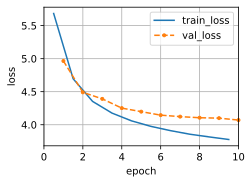

In [34]:
trainer = d2l.Trainer(max_epochs=10, gradient_clip_val=1, num_gpus=1)
t0 = time.perf_counter()
trainer.fit(model, data)
t_concise = time.perf_counter() - t0

With the same initialization, data, and training, the concise model
reaches about the same validation perplexity as the scratch model, and its
samples read the same.

In [35]:
ppl_concise = math.exp(trainer.history['val_loss'][-1])
pred = model.predict('The Time Traveller', 30, data.tokenizer, d2l.try_gpu())
d2l.print_wrapped(f'perplexity {ppl_concise:.1f}, {pred!r}')

perplexity 58.6, "The Time Traveller,\nand\nwelling\ndisappeared to
    me.\n\n'I had\ndaying\nthe Time Traveller,"


### Scratch and Concise Implementations Compared

Both training runs were timed, so we can put the two implementations side
by side. Each time covers the whole call to `fit`: ten epochs of training,
validation after every epoch, and the loading of every minibatch.

In [36]:
print(f'{"model":>8} {"time (s)":>9} {"val ppl":>8}')
for name, t, p in [('scratch', t_scratch, ppl_scratch),
                   ('concise', t_concise, ppl_concise)]:
    print(f'{name:>8} {t:>9.1f} {p:>8.1f}')

   model  time (s)  val ppl
 scratch      12.8     59.7
 concise       5.9     58.6


The framework layer is two to three times faster. `nn.RNN` runs the whole
recurrence in one fused cuDNN kernel, while our scratch loop launches
several small GPU operations per time step from Python, and at this model
size the cost of each launch outweighs the arithmetic it starts. Both times
also include the same data loading and validation, so the recurrences alone
differ by more than the totals do.

At this model size the difference is seconds to tens of seconds. The
overhead of the scratch loop arises once per time step, so it grows with
the length of the sequences and the number of stacked layers. The rest of
the book therefore writes recurrent cells from scratch only to explain them,
and trains with the framework layers.

The model we have built reads a window of 32 tokens and keeps a 128-number
state. With a wider embedding and dropout, it predicts the next token about
as well as a Kneser–Ney trigram, and averaged with that trigram it beats
both. A plain RNN still has trouble carrying information across many
steps, because its gradients pass through the same transition at every
step. that section computes these gradients and shows when they
vanish or explode.

## Summary

An RNN language model keeps one contract at every time step: it consumes a
token and the previous state and returns logits and a new state of the same
shape. We implemented it from tensor operations, with an embedding lookup in
place of one-hot inputs, a tanh cell, and an output layer shared by all
steps, and then with each framework's recurrent layer, initialized and
trained the same way. Gradients through many steps can explode, so every
update clips the gradient norm, which bounds the change any one update
makes. Each training window starts from a zero state, which truncates
backpropagation at the window length. Under SGD the embedding rows barely
move, and the plain model overfits, reaching 2.3 to 2.4 bits per byte. A wider
embedding with dropout lowers the validation loss to about 2.1 bits per
byte, within a few hundredths of a Kneser–Ney trigram on the same text, and
the average of the two models beats both. Greedy generation falls into
loops, and temperature sampling replaces them with invented words.

## Exercises

1. [code] **Gradient clipping ablation.** `d2l.Trainer` applies the
   projection the equation whenever `gradient_clip_val` is
   positive.
    1. Record the norm of the gradient before clipping at every update
       of the first epoch, and plot it. How often does clipping act, and
       when?
    1. Train `RNNLMScratch` three times with `gradient_clip_val=0` at
       `lr=4`. How many runs diverge or end far above the validation
       perplexity of the clipped run? Then halve the learning rate until
       three unclipped runs in a row train without a blow-up. How does
       their validation perplexity after ten epochs compare with that of
       the clipped run at `lr=4`?
    1. Replace $\tanh$ by ReLU in `RNNScratch` and train again, with and
       without clipping. Is clipping still needed? Explain the difference
       from the $\tanh$ cell in terms of the range of the hidden state.

1. [code] **Usable history.** Every training window starts from a zero
   state, so the model is never trained to use more than `num_steps`
   tokens of context. `predict`, by contrast, carries the state across
   the whole prefix and every generated token. Evaluate the trained model
   on 512 consecutive validation tokens in two ways: resetting the state
   to zero every 32 tokens as in training, and carrying the state across
   all 512 tokens. Compare the average cross-entropy of the two. Does the
   carried state help, hurt, or make no difference, and what does the
   answer say about the states the model reaches beyond its training
   horizon?

1. [code] **Hyperparameters and data budget.**
    1. Starting from the model with the wider embedding, adjust the
       number of epochs, hidden units, embedding dimension, `num_steps`,
       learning rate, and dropout rates, or add weight decay, to lower the
       validation perplexity. Can the RNN alone, trained with SGD, beat
       the Kneser–Ney trigram? How does the relative improvement in bits
       per byte compare with the relative improvement in perplexity, and
       why?
    1. Restore the pipeline default `num_train=10000` and train for 100
       epochs. Compare the training and validation perplexity curves and
       explain what you see. Consecutive windows overlap by 31 tokens, so
       how many parameters does the model have per distinct training
       token in this regime?

1. [code] **Adam.** Train the model with the wider embedding with the Adam
   optimizer of that section instead of SGD: subclass
   `RNNLMScratch`, override `configure_optimizers` to return Adam with
   learning rate 0.003, and keep clipping at 1.
    1. With `emb_dropout=0.2`, score the tokens `val[32:]` as in the
       comparison above, and compare its bits per byte with the SGD
       model, the Kneser–Ney trigram and 4-gram, and the mixture of the
       RNN and the trigram at $\lambda = 0.5$.
    1. Record the validation loss after every epoch, with
       `emb_dropout=0.1` and with 0.2. At which epoch is it lowest, and what
       happens after that?
    1. Measure again how far the embedding rows move during training. Why
       does Adam move them further than SGD does?

1. [code] **Scratch versus concise timing.** `t_scratch` and `t_concise`
   time ten epochs of `RNNLMScratch` and `RNNLM` with 128 hidden units,
   32-token windows, and a batch size of 1,024.
    1. Vary `num_hiddens` over 32, 128, and 512 and `num_steps` over 16,
       32, and 128, and tabulate the ratio `t_scratch / t_concise` for
       each setting. In which direction does the ratio move with each
       hyperparameter?
    1. Repeat the default setting with a batch size of 64. Explain the
       changes you measure: which of per-step launch overhead, arithmetic
       per step, and compilation dominates in each regime?

1. [code] **Vocabulary size and bits per byte.** ● Rebuild the dataset with
   `vocab_size` set to 512, 1,024, 2,048, and 4,096 in `d2l.TimeMachine` and
   retrain with the same architecture and training procedure. The number of
   windows `len(data.X)` depends on the vocabulary size, so replace the
   fixed split of 50,000 training and 5,000 validation windows by a
   fractional one. Build each dataset once to read off the number of windows
   `n = len(data.X)`, then build it again, passing `num_train=int(0.8 * n)`
   and `num_val=n - int(0.8 * n)` to the constructor; setting
   `data.num_train` afterwards would skip the step that keeps validation
   tokens out of the training targets. Every model then trains and validates
   on about the same stretch of text. The per-token perplexities of these
   models are not comparable, so compare them by bits per byte.
    1. Which vocabulary size gives the lowest bits per byte?
    1. How do the parameter counts of the embedding table and the output
       layer, and the length of the corpus in tokens, change with the
       vocabulary size? Which of these effects best explains the trend
       you measured?

1. [code] **Weight tying.** ● Weight tying sets the embedding dimension
   equal to the number of hidden units and uses $\mathbf{E}^\top$ as the
   output projection in place of $\mathbf{W}_{\textrm{hq}}$
   [@Press.Wolf.2017; @Inan.Khosravi.Socher.2017].
    1. How many parameters does tying save at $|\mathcal{V}| = 1{,}027$
       with 128 hidden units? GPT-2 small ties its $50{,}257 \times 768$
       token embedding to its output layer. How many parameters would
       untying add there, and what fraction of the model's roughly 124
       million parameters is that?
    1. Tie the weights in `RNNLMScratch` with an embedding dimension of 128.
       `RNNLMScratch` initializes $\mathbf{E}$ at unit scale
       and $\mathbf{W}_{\textrm{hq}}$ at scale `sigma`. What happens to
       the initial perplexity once the two are tied, and how do you
       restore a near-uniform initial prediction?
    1. Train the tied model and an untied model with a 128-dimensional
       embedding and 128 hidden units, and compare their validation
       perplexities.

1. [code] **Cross-book generalization.** ● Subclass `d2l.TimeMachine` and
   override `_download` to return the text of a different H. G. Wells
   novel, such as *The War of the Worlds* (Project Gutenberg ebook 36).
   Train the tokenizer and the model on it.
    1. Evaluate the model on held-out text of its own novel and on *The
       Time Machine*, encoding both with the new novel's tokenizer.
       Report perplexity and bits per byte for both.
    1. Write $s = \log_2(\textrm{ppl})$ for the per-token surprisal and
       $b$ for the bytes per token of an evaluated text, so that bits per
       byte is $s / b$. The ratio of bits per byte on *The Time Machine*
       (TM) to bits per byte on the held-out text of the new novel (own)
       factors as
       $$\frac{s_\textrm{TM}}{s_\textrm{own}} \cdot \frac{b_\textrm{own}}{b_\textrm{TM}}.$$
       The first factor reflects the model's predictions and the second
       the tokenizer's compression. Measure both factors. Which lies
       further from one?

[Discussions](https://d2l.discourse.group/t/486)